# Stage 2 - Standard CIFAR-10 ResNet-18 (Google Colab)

This notebook prepares the already validated standard-model training recipe for Google Colab. It does not change the model, data, optimizer, schedule, augmentation, or evaluation plan.

The Colab timing check uses a temporary model and a short subset of training batches. It does not write or alter an official checkpoint. Official training is disabled by default and must be explicitly enabled after reviewing the timing result. The earlier local checks and one-epoch timing probe do not count toward the official run; the official model starts from a fresh initialization at epoch 0.

Before running, copy the project folder to Google Drive, including:
- src/models.py
- data/raw/cifar-10-batches-py/
- data/splits/clean_test_split_seed42.npz
- data/splits/clean_test_split_seed43.npz
- data/splits/clean_test_split_seed44.npz

This notebook uses only the CIFAR-10 training set for optimization. Calibration/evaluation indices are checked for presence and disjointness but are not used for training or checkpoint selection.

## 1. Colab runtime and accelerator check

The official run requires an NVIDIA CUDA GPU. The cell reports Python, PyTorch, CUDA, GPU model, and available GPU memory, then stops if CUDA is unavailable. cuDNN benchmarking is enabled for the fixed 32x32 image size.

In [1]:
import gc
import csv
import json
import math
import os
import platform
import random
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torchvision
from torch import nn
from torch.utils.data import DataLoader
from torchvision import transforms
from torchvision.datasets import CIFAR10

print(f"Python: {platform.python_version()}")
print(f"PyTorch: {torch.__version__}")
print(f"torchvision: {torchvision.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")

if not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA is required for the official training run. In Colab, select "
        "Runtime > Change runtime type > T4 GPU (or another CUDA GPU), then rerun."
    )

DEVICE = torch.device("cuda:0")
GPU_NAME = torch.cuda.get_device_name(DEVICE)
GPU_PROPERTIES = torch.cuda.get_device_properties(DEVICE)
GPU_MEMORY_GIB = GPU_PROPERTIES.total_memory / (1024 ** 3)
print(f"Selected device: {DEVICE}")
print(f"GPU name: {GPU_NAME}")
print(f"GPU memory: {GPU_MEMORY_GIB:.2f} GiB")

# Fixed 32x32 inputs allow cuDNN to select fast convolution algorithms.
torch.backends.cudnn.benchmark = True
print(f"torch.backends.cudnn.benchmark: {torch.backends.cudnn.benchmark}")

Python: 3.13.15
PyTorch: 2.11.0+cu130
torchvision: 0.26.0+cu130
CUDA available: True
Selected device: cuda:0
GPU name: Tesla T4
GPU memory: 14.56 GiB
torch.backends.cudnn.benchmark: True


## 2. Project location and Drive persistence

Set the project root below. The default assumes a copy of this project folder is at My Drive/conformal_shift. You can change that path to match your Drive layout. Mounting Drive is optional, but it should remain enabled for persistent checkpoints and history.

The run output is stored in a dedicated folder under the project root. The notebook does not download data or recreate split indices. If the extracted CIFAR-10 Python batch directory is absent, setup extracts one matching CIFAR-10 batch ZIP already in the project root or data/raw.

In [2]:
import shutil
import zipfile

USE_GOOGLE_DRIVE = True
GOOGLE_DRIVE_PROJECT_ROOT = Path("/content/drive/MyDrive/conformal_shift")
PROJECT_ROOT_OVERRIDE = None  # Set a Path/string here to use a different project root.

if USE_GOOGLE_DRIVE:
    try:
        from google.colab import drive
    except ImportError as error:
        raise RuntimeError(
            "Google Drive mounting is available inside Google Colab. "
            "Set USE_GOOGLE_DRIVE=False and PROJECT_ROOT_OVERRIDE when running elsewhere."
        ) from error
    drive.mount("/content/drive")
    PROJECT_ROOT = Path(PROJECT_ROOT_OVERRIDE) if PROJECT_ROOT_OVERRIDE else GOOGLE_DRIVE_PROJECT_ROOT
else:
    PROJECT_ROOT = (
        Path(PROJECT_ROOT_OVERRIDE)
        if PROJECT_ROOT_OVERRIDE
        else Path("/content/conformal_shift")
    )

PROJECT_ROOT = PROJECT_ROOT.expanduser().resolve()
DATA_ROOT = PROJECT_ROOT / "data" / "raw"
SPLIT_DIR = PROJECT_ROOT / "data" / "splits"
MODEL_SOURCE = PROJECT_ROOT / "src" / "models.py"
OUTPUT_DIR = PROJECT_ROOT / "checkpoints" / "resnet18_standard_colab"
DATA_ROOT.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CIFAR_BATCH_DIR = DATA_ROOT / "cifar-10-batches-py"
CIFAR_BATCH_FILES = [
    "data_batch_1", "data_batch_2", "data_batch_3",
    "data_batch_4", "data_batch_5", "test_batch", "batches.meta",
]
if not all((CIFAR_BATCH_DIR / name).is_file() for name in CIFAR_BATCH_FILES):
    archive_candidates = {
        path.resolve()
        for pattern in ("cifar-10-batches-py*.zip",)
        for search_root in (PROJECT_ROOT, DATA_ROOT)
        for path in search_root.glob(pattern)
    }
    if len(archive_candidates) != 1:
        raise FileNotFoundError(
            "Expected the extracted CIFAR-10 Python batches under data/raw/cifar-10-batches-py "
            "or exactly one cifar-10-batches-py*.zip in the project root/data/raw. "
            f"Found archives: {sorted(str(path) for path in archive_candidates)}"
        )
    archive_path = next(iter(archive_candidates))
    expected_members = [
        f"cifar-10-batches-py/{filename}" for filename in CIFAR_BATCH_FILES
    ]
    with zipfile.ZipFile(archive_path, "r") as archive:
        archive_members = set(archive.namelist())
        missing_members = sorted(set(expected_members) - archive_members)
        if missing_members:
            raise ValueError(f"The CIFAR-10 archive is missing expected files: {missing_members}")
        bad_member = archive.testzip()
        if bad_member is not None:
            raise ValueError(f"CIFAR-10 ZIP CRC check failed for: {bad_member}")
        CIFAR_BATCH_DIR.mkdir(parents=True, exist_ok=True)
        for member in expected_members:
            destination = CIFAR_BATCH_DIR / Path(member).name
            with archive.open(member, "r") as source, destination.open("wb") as target:
                target.write(source.read())
    print(f"Extracted the CIFAR-10 Python batches from: {archive_path}")

print(f"Project root: {PROJECT_ROOT}")
print(f"Data root: {DATA_ROOT}")
print(f"Output directory: {OUTPUT_DIR}")
print(f"CIFAR-10 batch directory: {CIFAR_BATCH_DIR}")

required_paths = [
    MODEL_SOURCE,
    *[CIFAR_BATCH_DIR / name for name in CIFAR_BATCH_FILES],
    *[SPLIT_DIR / f"clean_test_split_seed{seed}.npz" for seed in (42, 43, 44)],
]
missing_paths = [str(path) for path in required_paths if not path.is_file()]
if missing_paths:
    raise FileNotFoundError(
        "Project files are missing. Copy the project data, src/models.py, and split files "
        f"to the configured Drive project root. Missing: {missing_paths}"
    )

# Confirm each saved split remains disjoint and has the expected sizes.
for split_seed in (42, 43, 44):
    split_path = SPLIT_DIR / f"clean_test_split_seed{split_seed}.npz"
    with np.load(split_path, allow_pickle=False) as split:
        calibration_indices = split["calibration_indices"].astype(np.int64)
        evaluation_indices = split["evaluation_indices"].astype(np.int64)
    if calibration_indices.size != 5_000 or evaluation_indices.size != 5_000:
        raise ValueError(f"Unexpected split sizes in {split_path}")
    if np.intersect1d(calibration_indices, evaluation_indices).size:
        raise ValueError(f"Calibration/evaluation overlap in {split_path}")
print("Project files and all three disjoint split files: PASS")

sys.path.insert(0, str(PROJECT_ROOT))
from src.models import resnet18_cifar

Mounted at /content/drive
Project root: /content/drive/MyDrive/conformal_shift
Data root: /content/drive/MyDrive/conformal_shift/data/raw
Output directory: /content/drive/MyDrive/conformal_shift/checkpoints/resnet18_standard_colab
CIFAR-10 batch directory: /content/drive/MyDrive/conformal_shift/data/raw/cifar-10-batches-py
Project files and all three disjoint split files: PASS


## 3. Fixed training configuration

These values match the locally validated recipe. AMP is configurable and enabled initially for Colab. The CUDA timing cell will verify that this setting works. If AMP raises an error, set USE_AMP=False and rerun the runtime from a clean state instead of repeatedly changing packages.

The DataLoader uses two workers and pinned memory, a conservative starting point for Colab. cuDNN benchmarking is enabled as requested; random seeds are fixed, while strict deterministic-kernel mode is not forced. Keep this CUDA autocast and GradScaler setup, together with cuDNN benchmarking, the same in the later Colab AugMix run.

In [9]:
SEED = 42
EPOCHS = 75
BATCH_SIZE = 64
INITIAL_LR = 0.05
MOMENTUM = 0.9
WEIGHT_DECAY = 5e-4
NUM_WORKERS = 2
PIN_MEMORY = True
USE_AMP = True
RESUME_TRAINING = False
RUN_OFFICIAL_TRAINING = False

CIFAR_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR_STD = (0.2470, 0.2435, 0.2616)

TRAINING_CONFIG = {
    "run_name": "standard_resnet18_cifar10",
    "model": "CIFAR-style ResNet-18",
    "stem_kernel_size": 3,
    "stem_stride": 1,
    "initial_maxpool": False,
    "pretrained_weights": None,
    "num_classes": 10,
    "seed": SEED,
    "epochs": EPOCHS,
    "batch_size": BATCH_SIZE,
    "optimizer": "SGD",
    "initial_lr": INITIAL_LR,
    "momentum": MOMENTUM,
    "weight_decay": WEIGHT_DECAY,
    "scheduler": "CosineAnnealingLR",
    "scheduler_t_max": EPOCHS,
    "scheduler_eta_min": 0.0,
    "augmentation": ["RandomCrop(32, padding=4)", "RandomHorizontalFlip()"],
    "normalization_mean": list(CIFAR_MEAN),
    "normalization_std": list(CIFAR_STD),
    "num_workers": NUM_WORKERS,
    "pin_memory": PIN_MEMORY,
    "use_amp": USE_AMP,
    "cudnn_benchmark": True,
}
print(json.dumps(TRAINING_CONFIG, indent=2))
print(f"RESUME_TRAINING: {RESUME_TRAINING}")
print(f"RUN_OFFICIAL_TRAINING: {RUN_OFFICIAL_TRAINING}")

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything(SEED)

{
  "run_name": "standard_resnet18_cifar10",
  "model": "CIFAR-style ResNet-18",
  "stem_kernel_size": 3,
  "stem_stride": 1,
  "initial_maxpool": false,
  "pretrained_weights": null,
  "num_classes": 10,
  "seed": 42,
  "epochs": 75,
  "batch_size": 64,
  "optimizer": "SGD",
  "initial_lr": 0.05,
  "momentum": 0.9,
  "weight_decay": 0.0005,
  "scheduler": "CosineAnnealingLR",
  "scheduler_t_max": 75,
  "scheduler_eta_min": 0.0,
  "augmentation": [
    "RandomCrop(32, padding=4)",
    "RandomHorizontalFlip()"
  ],
  "normalization_mean": [
    0.4914,
    0.4822,
    0.4465
  ],
  "normalization_std": [
    0.247,
    0.2435,
    0.2616
  ],
  "num_workers": 2,
  "pin_memory": true,
  "use_amp": true,
  "cudnn_benchmark": true
}
RESUME_TRAINING: False
RUN_OFFICIAL_TRAINING: False


## 4. CIFAR-10 training data

The official model uses the 50,000 CIFAR-10 training images only. The official test data is not loaded in this training notebook. The split files are reserved for later evaluation after the model is fixed.

In [4]:
train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD),
])

train_dataset = CIFAR10(
    root=str(DATA_ROOT),
    train=True,
    download=False,
    transform=train_transform,
)
if len(train_dataset) != 50_000:
    raise ValueError(f"Expected 50,000 CIFAR-10 training images; found {len(train_dataset)}")
if tuple(train_dataset[0][0].shape) != (3, 32, 32):
    raise ValueError(f"Unexpected image shape: {train_dataset[0][0].shape}")
print(f"Training images: {len(train_dataset):,}")
print(f"Input tensor shape: {tuple(train_dataset[0][0].shape)}")
print(f"Normalization mean: {CIFAR_MEAN}")
print(f"Normalization std: {CIFAR_STD}")

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % (2 ** 32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)

def make_train_loader(generator):
    loader_kwargs = {
        "dataset": train_dataset,
        "batch_size": BATCH_SIZE,
        "shuffle": True,
        "num_workers": NUM_WORKERS,
        "pin_memory": PIN_MEMORY,
        "generator": generator,
        "worker_init_fn": seed_worker,
        "drop_last": False,
    }
    if NUM_WORKERS > 0:
        loader_kwargs["persistent_workers"] = False
        loader_kwargs["prefetch_factor"] = 2
    return DataLoader(**loader_kwargs)

Training images: 50,000
Input tensor shape: (3, 32, 32)
Normalization mean: (0.4914, 0.4822, 0.4465)
Normalization std: (0.247, 0.2435, 0.2616)


## 5. Official checkpoint detection

The notebook does not automatically resume. It reports whether an official checkpoint exists and, if so, prints its completed epoch and saved configuration. Before resuming, the training cell verifies that the saved configuration exactly matches the configuration above.

If no official checkpoint exists and RUN_OFFICIAL_TRAINING is enabled, the model, optimizer, scheduler, and AMP scaler are freshly initialized at epoch 0. The temporary timing model is never reused.

In [7]:
LATEST_CHECKPOINT_PATH = OUTPUT_DIR / "latest_checkpoint.pt"
FINAL_CHECKPOINT_PATH = OUTPUT_DIR / "final_checkpoint.pt"
FINAL_MODEL_PATH = OUTPUT_DIR / "final_model.pt"
CONFIG_PATH = OUTPUT_DIR / "training_config.json"
HISTORY_PATH = OUTPUT_DIR / "training_history.csv"
LOSS_HISTORY_PATH = OUTPUT_DIR / "training_loss_history.csv"
LR_HISTORY_PATH = OUTPUT_DIR / "learning_rate_history.csv"

def checkpoint_candidate():
    if LATEST_CHECKPOINT_PATH.is_file():
        return LATEST_CHECKPOINT_PATH
    if FINAL_CHECKPOINT_PATH.is_file():
        return FINAL_CHECKPOINT_PATH
    return None

existing_checkpoint_path = checkpoint_candidate()
if existing_checkpoint_path is None:
    print("No official checkpoint found -> an explicitly enabled run will start fresh at epoch 0.")
else:
    existing_state = torch.load(
        existing_checkpoint_path, map_location="cpu", weights_only=False
    )
    required_checkpoint_keys = {
        "checkpoint_type", "epoch_completed", "config", "model_state_dict",
        "optimizer_state_dict", "scheduler_state_dict", "scaler_state_dict",
        "history", "loader_generator_state", "python_rng_state",
        "numpy_rng_state", "torch_rng_state", "cuda_rng_state",
    }
    if not required_checkpoint_keys.issubset(existing_state):
        raise ValueError(f"Checkpoint is missing required resume fields: {existing_checkpoint_path}")
    if existing_state["checkpoint_type"] != "official_resnet18_standard":
        raise ValueError("The found checkpoint is not an official standard ResNet-18 run.")
    print(f"Official checkpoint found: {existing_checkpoint_path}")
    print(f"Completed epoch: {existing_state['epoch_completed']}")
    print("Saved configuration:")
    print(json.dumps(existing_state["config"], indent=2))

Official checkpoint found: /content/drive/MyDrive/conformal_shift/checkpoints/resnet18_standard_colab/latest_checkpoint.pt
Completed epoch: 47
Saved configuration:
{
  "run_name": "standard_resnet18_cifar10",
  "model": "CIFAR-style ResNet-18",
  "stem_kernel_size": 3,
  "stem_stride": 1,
  "initial_maxpool": false,
  "pretrained_weights": null,
  "num_classes": 10,
  "seed": 42,
  "epochs": 75,
  "batch_size": 64,
  "optimizer": "SGD",
  "initial_lr": 0.05,
  "momentum": 0.9,
  "weight_decay": 0.0005,
  "scheduler": "CosineAnnealingLR",
  "scheduler_t_max": 75,
  "scheduler_eta_min": 0.0,
  "augmentation": [
    "RandomCrop(32, padding=4)",
    "RandomHorizontalFlip()"
  ],
  "normalization_mean": [
    0.4914,
    0.4822,
    0.4465
  ],
  "normalization_std": [
    0.247,
    0.2435,
    0.2616
  ],
  "num_workers": 2,
  "pin_memory": true,
  "use_amp": true,
  "cudnn_benchmark": true
}


## 6. Recoverable training loop

The official loop is fixed at 75 epochs and uses only the CIFAR-10 training set. It does not evaluate calibration/evaluation examples for model selection. After every epoch, it saves the model, optimizer, scheduler, AMP scaler, random states, completed epoch, configuration, and full history to Drive.

Training is disabled by default. To launch only after reviewing the timing check, set RUN_OFFICIAL_TRAINING=True. Leave RESUME_TRAINING=False for a fresh run; set it to True only when you explicitly want to resume a matching saved run.

Resuming from completed epoch 75.


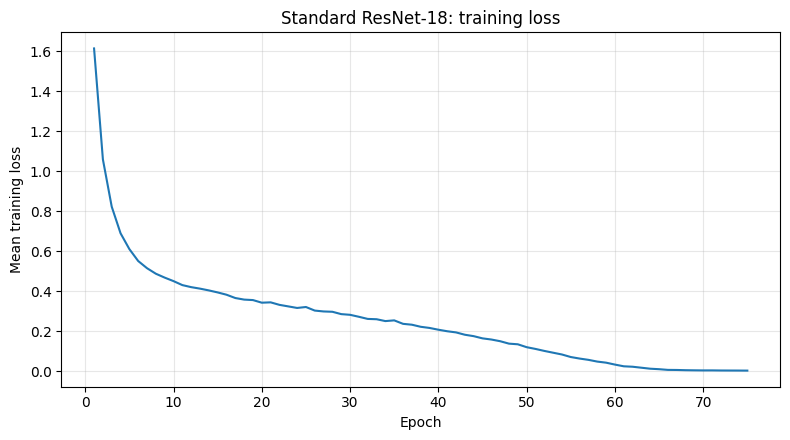

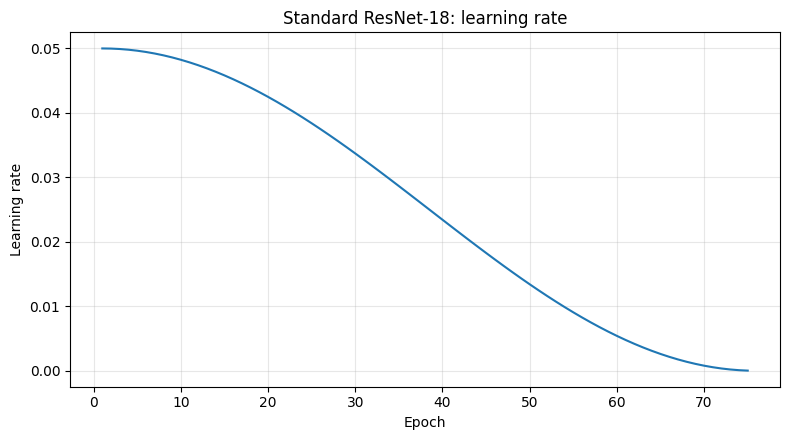

Final training loss: 0.0037
Total active training time: 0.62 hours
Final model: /content/drive/MyDrive/conformal_shift/checkpoints/resnet18_standard_colab/final_model.pt
Final recoverable checkpoint: /content/drive/MyDrive/conformal_shift/checkpoints/resnet18_standard_colab/final_checkpoint.pt
Latest recoverable checkpoint: /content/drive/MyDrive/conformal_shift/checkpoints/resnet18_standard_colab/latest_checkpoint.pt


In [11]:
def write_history_csv(history):
    fieldnames = [
        "epoch", "mean_train_loss", "learning_rate",
        "epoch_seconds", "cumulative_elapsed_seconds",
    ]
    temporary_path = HISTORY_PATH.with_suffix(".tmp")
    with temporary_path.open("w", newline="", encoding="utf-8") as output_file:
        writer = csv.DictWriter(output_file, fieldnames=fieldnames)
        writer.writeheader()
        writer.writerows(history)
    os.replace(temporary_path, HISTORY_PATH)

    with LOSS_HISTORY_PATH.open("w", newline="", encoding="utf-8") as output_file:
        writer = csv.writer(output_file)
        writer.writerow(["epoch", "mean_train_loss"])
        writer.writerows((row["epoch"], row["mean_train_loss"]) for row in history)

    with LR_HISTORY_PATH.open("w", newline="", encoding="utf-8") as output_file:
        writer = csv.writer(output_file)
        writer.writerow(["epoch", "learning_rate"])
        writer.writerows((row["epoch"], row["learning_rate"]) for row in history)

def save_checkpoint(path, state):
    temporary_path = path.with_name(path.name + ".tmp")
    torch.save(state, temporary_path)
    os.replace(temporary_path, path)

def plot_training_history(history):
    epochs = [row["epoch"] for row in history]
    losses = [row["mean_train_loss"] for row in history]
    learning_rates = [row["learning_rate"] for row in history]

    plt.figure(figsize=(8, 4.5))
    plt.plot(epochs, losses)
    plt.xlabel("Epoch")
    plt.ylabel("Mean training loss")
    plt.title("Standard ResNet-18: training loss")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "training_loss.png", dpi=160)
    plt.show()

    plt.figure(figsize=(8, 4.5))
    plt.plot(epochs, learning_rates)
    plt.xlabel("Epoch")
    plt.ylabel("Learning rate")
    plt.title("Standard ResNet-18: learning rate")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "learning_rate.png", dpi=160)
    plt.show()

def official_training():
    candidate = checkpoint_candidate()
    if candidate is not None and not RESUME_TRAINING:
        raise RuntimeError(
            f"An official checkpoint exists at {candidate}. Set RESUME_TRAINING=True "
            "to resume after verifying the displayed configuration, or select a new "
            "output directory before starting a separate fresh run."
        )
    if candidate is None and RESUME_TRAINING:
        raise FileNotFoundError("RESUME_TRAINING=True but no official checkpoint was found.")

    if CONFIG_PATH.exists():
        saved_config = json.loads(CONFIG_PATH.read_text(encoding="utf-8"))
        if saved_config != TRAINING_CONFIG:
            raise ValueError(
                f"Saved configuration differs from this notebook: {CONFIG_PATH}. "
                "Do not resume with changed settings."
            )
    else:
        other_outputs = [
            path for path in (
                HISTORY_PATH, LOSS_HISTORY_PATH, LR_HISTORY_PATH, FINAL_MODEL_PATH
            ) if path.exists()
        ]
        if other_outputs:
            raise FileExistsError(
                f"Training outputs exist without a checkpoint: {other_outputs}. "
                "Preserve them and choose a new output directory."
            )
        CONFIG_PATH.write_text(json.dumps(TRAINING_CONFIG, indent=2), encoding="utf-8")

    seed_everything(SEED)
    model = resnet18_cifar(num_classes=10).to(DEVICE)
    optimizer = torch.optim.SGD(
        model.parameters(),
        lr=INITIAL_LR,
        momentum=MOMENTUM,
        weight_decay=WEIGHT_DECAY,
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=EPOCHS, eta_min=0.0
    )
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    loader_generator = torch.Generator().manual_seed(SEED)
    train_loader = make_train_loader(loader_generator)
    history = []
    start_epoch = 0

    if candidate is not None:
        state = torch.load(candidate, map_location=DEVICE, weights_only=False)
        if state["config"] != TRAINING_CONFIG:
            raise ValueError("Checkpoint configuration does not match the current recipe.")
        model.load_state_dict(state["model_state_dict"])
        optimizer.load_state_dict(state["optimizer_state_dict"])
        scheduler.load_state_dict(state["scheduler_state_dict"])
        scaler.load_state_dict(state["scaler_state_dict"])
        history = state["history"]
        start_epoch = int(state["epoch_completed"])
        random.setstate(state["python_rng_state"])
        np.random.set_state(state["numpy_rng_state"])
        torch.set_rng_state(state["torch_rng_state"].cpu())
        torch.cuda.set_rng_state_all([value.cpu() for value in state["cuda_rng_state"]])
        loader_generator.set_state(state["loader_generator_state"].cpu())
        print(f"Resuming from completed epoch {start_epoch}.")
    else:
        print("Fresh official initialization: epoch 0, new model, optimizer, and scheduler.")

    if start_epoch > EPOCHS:
        raise ValueError(f"Checkpoint epoch {start_epoch} exceeds configured epochs {EPOCHS}.")
    cumulative_seconds = sum(float(row["epoch_seconds"]) for row in history)

    for epoch_index in range(start_epoch, EPOCHS):
        model.train()
        epoch_start = time.perf_counter()
        epoch_lr = float(optimizer.param_groups[0]["lr"])
        loss_sum = torch.zeros((), device=DEVICE)
        example_count = 0

        for images, labels in train_loader:
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast("cuda", dtype=torch.float16, enabled=USE_AMP):
                logits = model(images)
                loss = nn.functional.cross_entropy(logits, labels)
            if USE_AMP:
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            else:
                loss.backward()
                optimizer.step()
            loss_sum += loss.detach() * labels.size(0)
            example_count += labels.size(0)

        scheduler.step()
        torch.cuda.synchronize(DEVICE)
        epoch_seconds = time.perf_counter() - epoch_start
        cumulative_seconds += epoch_seconds
        mean_train_loss = (loss_sum / example_count).item()
        history.append({
            "epoch": epoch_index + 1,
            "mean_train_loss": mean_train_loss,
            "learning_rate": epoch_lr,
            "epoch_seconds": epoch_seconds,
            "cumulative_elapsed_seconds": cumulative_seconds,
        })
        write_history_csv(history)

        state = {
            "checkpoint_type": "official_resnet18_standard",
            "epoch_completed": epoch_index + 1,
            "config": TRAINING_CONFIG,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(),
            "scaler_state_dict": scaler.state_dict(),
            "history": history,
            "python_rng_state": random.getstate(),
            "numpy_rng_state": np.random.get_state(),
            "torch_rng_state": torch.get_rng_state(),
            "cuda_rng_state": torch.cuda.get_rng_state_all(),
            "loader_generator_state": loader_generator.get_state(),
        }
        save_checkpoint(LATEST_CHECKPOINT_PATH, state)
        print(
            f"Epoch {epoch_index + 1:02d}/{EPOCHS} | "
            f"train loss {mean_train_loss:.4f} | LR {epoch_lr:.6f} | "
            f"epoch {epoch_seconds / 60:.2f} min | "
            f"cumulative {cumulative_seconds / 3600:.2f} hr"
        )

    final_state = torch.load(
        LATEST_CHECKPOINT_PATH, map_location=DEVICE, weights_only=False
    )
    save_checkpoint(FINAL_CHECKPOINT_PATH, final_state)
    torch.save(final_state["model_state_dict"], FINAL_MODEL_PATH)
    plot_training_history(history)
    print(f"Final training loss: {history[-1]['mean_train_loss']:.4f}")
    print(f"Total active training time: {cumulative_seconds / 3600:.2f} hours")
    print(f"Final model: {FINAL_MODEL_PATH}")
    print(f"Final recoverable checkpoint: {FINAL_CHECKPOINT_PATH}")
    print(f"Latest recoverable checkpoint: {LATEST_CHECKPOINT_PATH}")
    return model, history

if RUN_OFFICIAL_TRAINING:
    final_model, official_history = official_training()
else:
    print("Official 75-epoch training is disabled. Timing only; no official state was changed.")

## 7. Outputs and review checkpoint

After a completed official run, the output folder contains latest_checkpoint.pt, final_checkpoint.pt, final_model.pt, training_config.json, training_history.csv, training_loss_history.csv, learning_rate_history.csv, training_loss.png, and learning_rate.png.

The saved checkpoint can resume after a Colab disconnect. Evaluation and conformal prediction are intentionally not run in this notebook. Review the Colab GPU timing and approve the official 75-epoch run separately.